# Fase 4. Modelado

En esta fase se selecciona la técnica de modelado, se define cómo se va a medir la calidad del modelo,
se construyen modelos con distintas cantidades de grupos y se elige el modelo final.

## 4.1 Selección de la técnica de modelado

Se utiliza K-Means, por las razones expuestas en la sección 1.5: permite asignar unidades nuevas a un
grupo (predicción), trabaja bien con las variables numéricas construidas en la sección 3 y sus
resultados se pueden evaluar con métricas estándar.

K-Means agrupa las unidades en K grupos de forma que cada unidad quede en el grupo cuyo centro
(centroide) esté más cerca. Como la cantidad de grupos K se debe definir antes de entrenar, se prueban
varios valores y se elige el más adecuado.

## 4.2 Diseño de la prueba del modelo

En un problema no supervisado no existe una respuesta correcta con la cual comparar, por lo que no se
separan datos de entrenamiento y de prueba. La calidad de los grupos se mide con métricas internas,
calculadas para cada valor de K entre 2 y 10:

| Métrica | Qué mide | Mejor valor |
|---|---|---|
| Inercia (método del codo) | Distancia de las unidades al centro de su grupo | Se busca el punto donde deja de bajar con fuerza |
| Silhouette Score | Qué tan bien separada está cada unidad de los otros grupos (de -1 a 1) | Más alto |
| Índice de Calinski-Harabasz | Relación entre la separación de los grupos y su dispersión interna | Más alto |
| Índice de Davies-Bouldin | Similitud promedio entre cada grupo y el más parecido | Más bajo |

Además de las métricas, se revisa el tamaño de los grupos y que los perfiles tengan sentido para el
negocio, según los criterios de éxito de la sección 1.4.

In [43]:
# Librerías utilizadas en esta fase
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

In [44]:
perfil_unidades = pd.read_csv(
    "../data/processed/perfil_unidades.csv",
    dtype={"codigo_unidad": str}
)
X_scaled = pd.read_csv("../data/processed/modelo_X_estandarizado.csv")

print("Unidades:", len(perfil_unidades))
print("Variables del modelo:", X_scaled.columns.tolist())

Unidades: 284
Variables del modelo: ['log_total_jefaturas', 'entropia_puestos', 'proporcion_puesto_principal']


## 4.3 Construcción de modelos con distintos valores de K

Se entrena un modelo K-Means para cada valor de K entre 2 y 10. Se usa random_state=42 para que los
resultados se puedan repetir y n_init=20 para que el algoritmo pruebe 20 puntos de partida distintos y
se quede con el mejor.

In [45]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

resultados_k = []

for k in range(2, 11):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    etiquetas = modelo.fit_predict(X_scaled)

    resultados_k.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silhouette": silhouette_score(
            X_scaled,
            etiquetas
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_scaled,
            etiquetas
        ),
        "davies_bouldin": davies_bouldin_score(
            X_scaled,
            etiquetas
        )
    })

resultados_k = pd.DataFrame(resultados_k)

resultados_k.round(3)

,k,inercia,silhouette,calinski_harabasz,davies_bouldin
0,2,205.372,0.699,887.895,0.399
1,3,119.605,0.647,860.348,0.589
2,4,55.690,0.727,1334.567,0.518
3,5,37.511,0.749,1514.522,0.575
4,6,27.225,0.759,1684.365,0.519
5,7,21.891,0.755,1750.614,0.527
6,8,16.596,0.747,1984.737,0.560
7,9,12.878,0.754,2239.870,0.574
8,10,10.309,0.746,2485.567,0.569


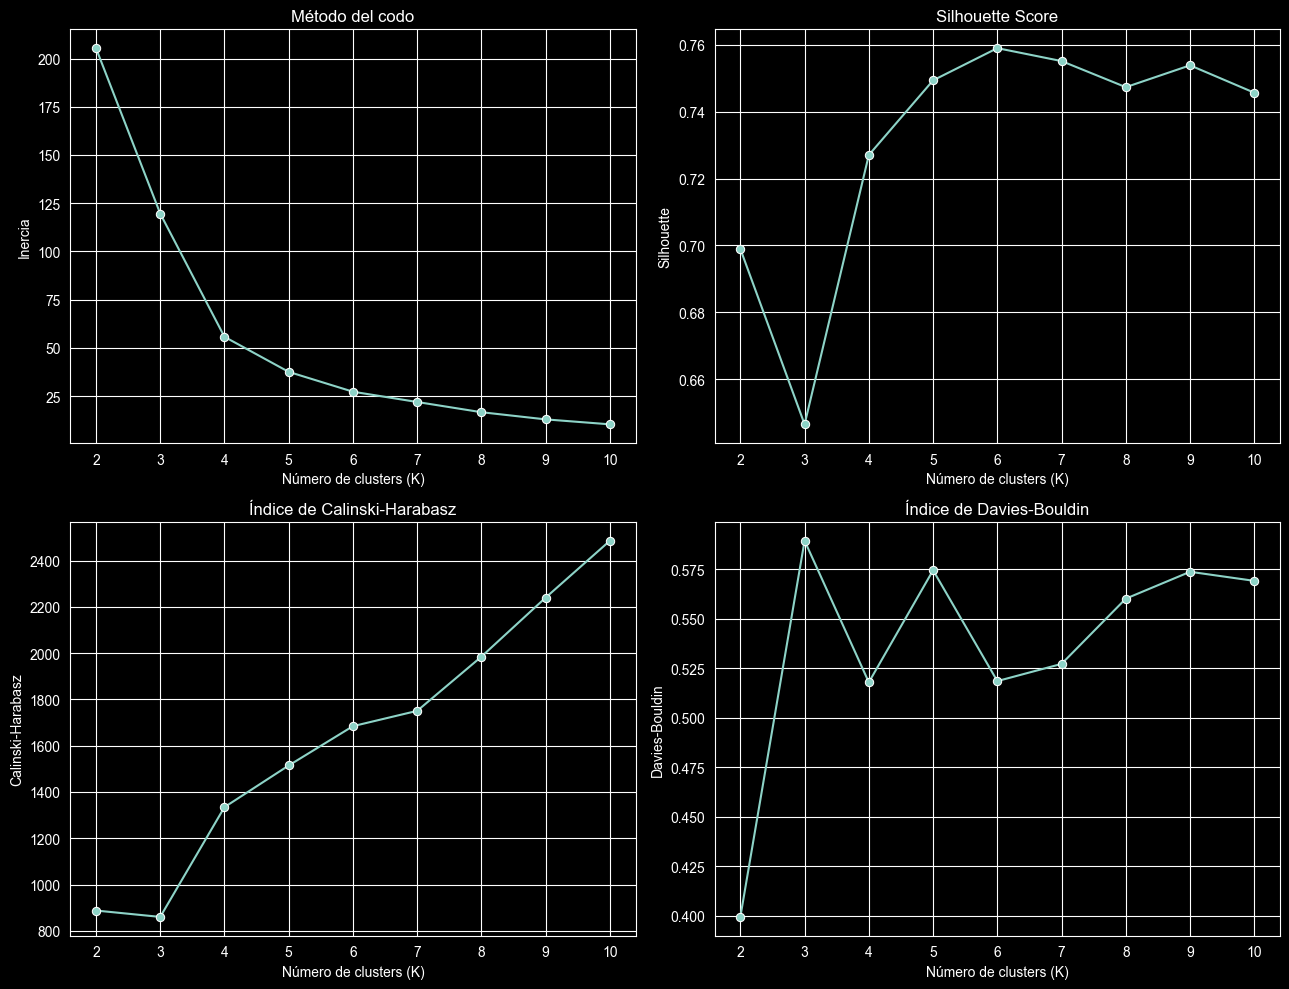

In [46]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 10)
)

sns.lineplot(
    data=resultados_k,
    x="k",
    y="inercia",
    marker="o",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Método del codo")
axes[0, 0].set_xlabel("Número de clusters (K)")
axes[0, 0].set_ylabel("Inercia")

sns.lineplot(
    data=resultados_k,
    x="k",
    y="silhouette",
    marker="o",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Silhouette Score")
axes[0, 1].set_xlabel("Número de clusters (K)")
axes[0, 1].set_ylabel("Silhouette")

sns.lineplot(
    data=resultados_k,
    x="k",
    y="calinski_harabasz",
    marker="o",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Índice de Calinski-Harabasz")
axes[1, 0].set_xlabel("Número de clusters (K)")
axes[1, 0].set_ylabel("Calinski-Harabasz")

sns.lineplot(
    data=resultados_k,
    x="k",
    y="davies_bouldin",
    marker="o",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Índice de Davies-Bouldin")
axes[1, 1].set_xlabel("Número de clusters (K)")
axes[1, 1].set_ylabel("Davies-Bouldin")

plt.tight_layout()
plt.show()

In [47]:
tamanos_por_k = {}

for k in range(2, 11):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    etiquetas = modelo.fit_predict(X_scaled)

    tamanos_por_k[k] = (
        pd.Series(etiquetas)
        .value_counts()
        .sort_index()
        .to_dict()
    )

tamanos_por_k

{2: {0: 106, 1: 178},
 3: {0: 138, 1: 106, 2: 40},
 4: {0: 89, 1: 98, 2: 58, 3: 39},
 5: {0: 98, 1: 89, 2: 39, 3: 29, 4: 29},
 6: {0: 29, 1: 89, 2: 98, 3: 35, 4: 29, 5: 4},
 7: {0: 89, 1: 98, 2: 29, 3: 35, 4: 7, 5: 22, 6: 4},
 8: {0: 89, 1: 96, 2: 20, 3: 28, 4: 23, 5: 7, 6: 17, 7: 4},
 9: {0: 15, 1: 89, 2: 17, 3: 95, 4: 7, 5: 20, 6: 4, 7: 20, 8: 17},
 10: {0: 89, 1: 39, 2: 17, 3: 20, 4: 20, 5: 17, 6: 4, 7: 15, 8: 7, 9: 56}}

### Revisión del tamaño de los conglomerados

Además de las métricas de calidad, se examinó la cantidad de unidades
asignadas a cada conglomerado para identificar soluciones excesivamente
fragmentadas.

Para K = 6, cinco conglomerados presentan tamaños comprendidos entre 29
y 98 unidades. Sin embargo, el sexto conglomerado contiene únicamente
cuatro unidades, equivalentes al 1.41 % del conjunto analizado.

La existencia de un conglomerado pequeño no invalida automáticamente el
modelo. Este grupo puede representar un perfil organizacional poco
frecuente, pero legítimo, compuesto por unidades notablemente diferentes
en tamaño, diversidad o concentración. No obstante, es necesario revisar
su composición antes de seleccionar definitivamente el modelo.

La solución K = 5 presenta grupos más equilibrados, con tamaños de 98,
89, 39, 29 y 29 unidades. Por su parte, las soluciones con siete o más
conglomerados generan progresivamente varios grupos de tamaño reducido,
sin producir una mejora clara y consistente en el Silhouette Score.

En consecuencia, la selección final se concentrará en comparar K = 5 y
K = 6. Se considerarán conjuntamente la calidad estadística, el tamaño de
los grupos y la utilidad de los perfiles obtenidos para la interpretación
del negocio.

## 4.4 Modelo con K = 6 y comparación con K = 5

In [48]:
modelo_k6 = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=20
)

perfil_unidades["cluster_k6"] = modelo_k6.fit_predict(
    X_scaled
)

tamanos_k6 = (
    perfil_unidades["cluster_k6"]
    .value_counts()
    .sort_index()
)

tamanos_k6

cluster_k6
0    29
1    89
2    98
3    35
4    29
5     4
Name: count, dtype: int64

In [49]:
cluster_menor = tamanos_k6.idxmin()

print("Cluster más pequeño:", cluster_menor)
print("Cantidad de unidades:", tamanos_k6.min())

unidades_cluster_menor = (
    perfil_unidades[
        perfil_unidades["cluster_k6"] == cluster_menor
    ][[
        "codigo_unidad",
        "unidad",
        "total_jefaturas",
        "puestos_distintos",
        "entropia_puestos",
        "proporcion_puesto_principal"
    ]]
    .sort_values(
        "total_jefaturas",
        ascending=False
    )
)

unidades_cluster_menor

Cluster más pequeño: 5
Cantidad de unidades: 4


,codigo_unidad,unidad,total_jefaturas,puestos_distintos,entropia_puestos,proporcion_puesto_principal
110,2102,Hospital San Juan de Dios,62,25,2.222825,0.500000
111,2103,Hospital Nacional de Niños Carlos Saenz Herrera,62,24,2.306275,0.451613
112,2104,Hospital México,62,24,2.271279,0.467742
109,2101,Hospital Rafael Ángel Calderón Guardia,52,21,2.256214,0.442308


In [50]:
perfil_k6 = (
    perfil_unidades
    .groupby("cluster_k6")
    .agg(
        unidades=(
            "codigo_unidad",
            "count"
        ),
        promedio_jefaturas=(
            "total_jefaturas",
            "mean"
        ),
        mediana_jefaturas=(
            "total_jefaturas",
            "median"
        ),
        promedio_puestos=(
            "puestos_distintos",
            "mean"
        ),
        entropia_promedio=(
            "entropia_puestos",
            "mean"
        ),
        concentracion_promedio=(
            "proporcion_puesto_principal",
            "mean"
        )
    )
    .round(3)
)

perfil_k6["porcentaje_unidades"] = (
    perfil_k6["unidades"]
    / len(perfil_unidades)
    * 100
).round(2)

perfil_k6

,unidades,promedio_jefaturas,mediana_jefaturas,promedio_puestos,entropia_promedio,concentracion_promedio,porcentaje_unidades
cluster_k6,,,,,,,
0,29,8.931,7.0,3.655,1.065,0.555,10.21
1,89,1.000,1.0,1.000,0.000,1.000,31.34
2,98,6.408,6.0,6.316,1.831,0.166,34.51
3,35,18.657,18.0,15.857,2.660,0.150,12.32
4,29,2.793,3.0,2.414,0.838,0.491,10.21
5,4,59.500,62.0,23.500,2.264,0.465,1.41


Modelo con K = 5 para comparar:

In [51]:
modelo_k5 = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20
)

perfil_unidades["cluster_k5"] = modelo_k5.fit_predict(
    X_scaled
)

perfil_k5 = (
    perfil_unidades
    .groupby("cluster_k5")
    .agg(
        unidades=(
            "codigo_unidad",
            "count"
        ),
        promedio_jefaturas=(
            "total_jefaturas",
            "mean"
        ),
        mediana_jefaturas=(
            "total_jefaturas",
            "median"
        ),
        promedio_puestos=(
            "puestos_distintos",
            "mean"
        ),
        entropia_promedio=(
            "entropia_puestos",
            "mean"
        ),
        concentracion_promedio=(
            "proporcion_puesto_principal",
            "mean"
        )
    )
    .round(3)
)

perfil_k5["porcentaje_unidades"] = (
    perfil_k5["unidades"]
    / len(perfil_unidades)
    * 100
).round(2)

perfil_k5

,unidades,promedio_jefaturas,mediana_jefaturas,promedio_puestos,entropia_promedio,concentracion_promedio,porcentaje_unidades
cluster_k5,,,,,,,
0,98,6.408,6.0,6.316,1.831,0.166,34.51
1,89,1.000,1.0,1.000,0.000,1.000,31.34
2,39,22.846,20.0,16.641,2.620,0.183,13.73
3,29,8.931,7.0,3.655,1.065,0.555,10.21
4,29,2.793,3.0,2.414,0.838,0.491,10.21


### Selección del modelo final

La comparación entre las soluciones K = 5 y K = 6 muestra que ambas
producen conglomerados estadísticamente consistentes. Sin embargo, K = 6
separa cuatro hospitales de escala excepcional que en K = 5 permanecían
agrupados con otras 35 unidades grandes.

El conglomerado adicional está compuesto por el Hospital San Juan de Dios,
el Hospital México, el Hospital Nacional de Niños Carlos Sáenz Herrera y
el Hospital Rafael Ángel Calderón Guardia. Estas unidades presentan entre
52 y 62 jefaturas y entre 21 y 25 puestos distintos.

Aunque este conglomerado contiene únicamente cuatro unidades, no se
considera una fragmentación arbitraria. Sus integrantes son instituciones
hospitalarias de alta complejidad, comparten una escala considerablemente
superior al resto y presentan un perfil estructural identificable.

La solución K = 6 también obtuvo el mayor Silhouette Score, con un valor
de 0.759, un índice de Calinski-Harabasz de 1684.365 y un índice de
Davies-Bouldin de 0.519.

Por estas razones, se seleccionó K = 6 como modelo principal. Esta solución
permite distinguir entre unidades unipersonales, estructuras pequeñas,
unidades medianas concentradas o diversificadas, unidades grandes altamente
diversificadas y hospitales de escala excepcional.

## 4.5 Perfiles de los grupos

Se asigna un nombre a cada grupo según sus características. K-Means numera los grupos de forma
arbitraria y esa numeración puede cambiar entre computadoras o versiones de las librerías. Por eso los
nombres no se asignan por número, sino ordenando los grupos de menor a mayor según su promedio de
jefaturas.

In [52]:
nombres_por_tamano = [
    "Unipersonales",
    "Pequeñas con diversidad moderada",
    "Medianas diversificadas",
    "Medianas con estructura concentrada",
    "Grandes y altamente diversificadas",
    "Hospitales de escala excepcional"
]

orden_clusters = perfil_k6["promedio_jefaturas"].sort_values().index
nombres_clusters = dict(zip(orden_clusters, nombres_por_tamano))

perfil_unidades["perfil_cluster"] = (
    perfil_unidades["cluster_k6"]
    .map(nombres_clusters)
)

perfil_k6["perfil_cluster"] = perfil_k6.index.map(nombres_clusters)
perfil_k6.sort_values("promedio_jefaturas")

,unidades,promedio_jefaturas,mediana_jefaturas,promedio_puestos,entropia_promedio,concentracion_promedio,porcentaje_unidades,perfil_cluster
cluster_k6,,,,,,,,
1,89,1.000,1.0,1.000,0.000,1.000,31.34,Unipersonales
4,29,2.793,3.0,2.414,0.838,0.491,10.21,Pequeñas con diversidad moderada
2,98,6.408,6.0,6.316,1.831,0.166,34.51,Medianas diversificadas
0,29,8.931,7.0,3.655,1.065,0.555,10.21,Medianas con estructura concentrada
3,35,18.657,18.0,15.857,2.660,0.150,12.32,Grandes y altamente diversificadas
5,4,59.500,62.0,23.500,2.264,0.465,1.41,Hospitales de escala excepcional


In [53]:
perfil_unidades[[
    "codigo_unidad",
    "unidad",
    "cluster_k6",
    "perfil_cluster"
]].head()

,codigo_unidad,unidad,cluster_k6,perfil_cluster
0,1100,Gerencia General,1,Unipersonales
1,1101,Junta Directiva,4,Pequeñas con diversidad moderada
2,1102,Presidencia Ejecutiva,1,Unipersonales
3,1103,Gerencia Financiera,4,Pequeñas con diversidad moderada
4,1104,Gerencia Administrativa,4,Pequeñas con diversidad moderada


## Visualización final de los grupos

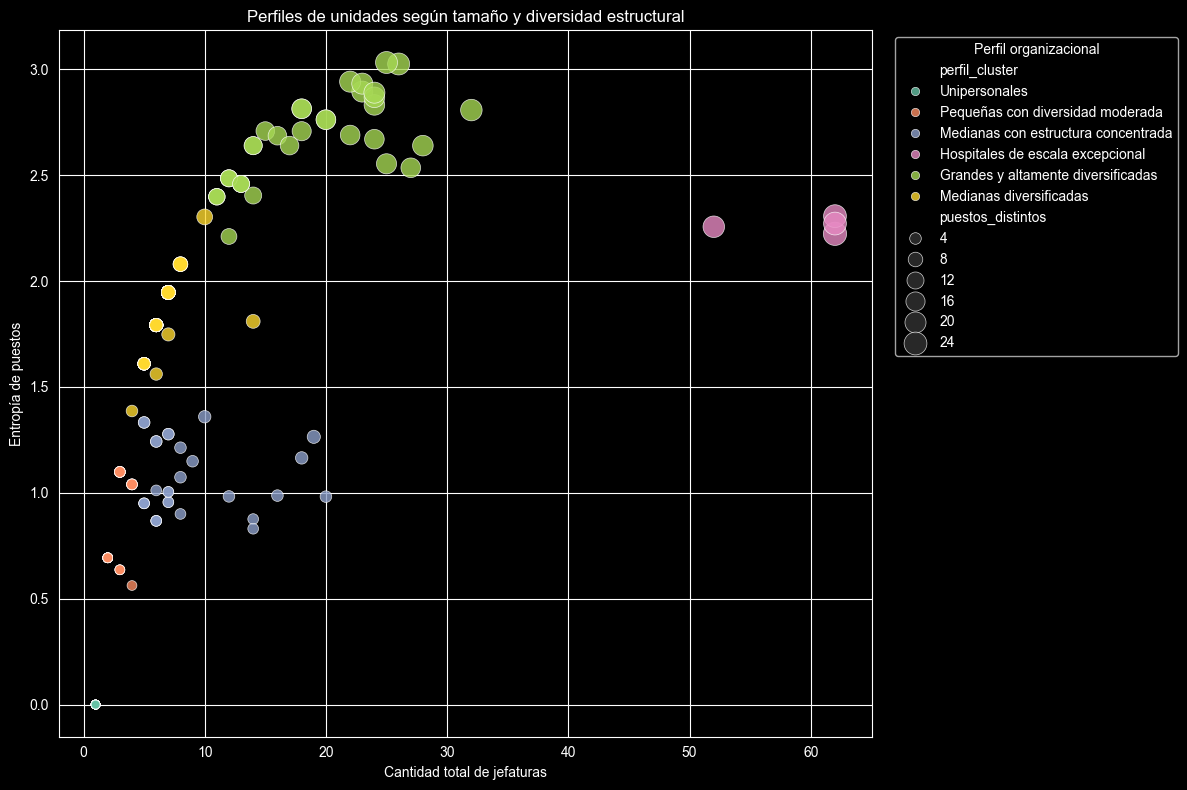

In [54]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=perfil_unidades,
    x="total_jefaturas",
    y="entropia_puestos",
    hue="perfil_cluster",
    size="puestos_distintos",
    palette="Set2",
    sizes=(40, 280),
    alpha=0.8
)

plt.title(
    "Perfiles de unidades según tamaño y diversidad estructural"
)
plt.xlabel("Cantidad total de jefaturas")
plt.ylabel("Entropía de puestos")

plt.legend(
    title="Perfil organizacional",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

## 4.6 Calidad de los grupos

Además de las métricas generales de la sección 4.3, se revisa la calidad de cada grupo por separado,
el efecto de las unidades con una sola jefatura, la separación visual de los grupos y las
diferencias entre los perfiles.

### Silueta por grupo

El Silhouette Score de 0.759 es el promedio de la silueta de las 284 unidades. Se calcula la silueta
de cada unidad para ver qué grupos están bien definidos y si hay unidades mal asignadas (silueta
cercana a 0 o negativa).

In [55]:
from sklearn.metrics import silhouette_samples

perfil_unidades["silueta"] = silhouette_samples(X_scaled, perfil_unidades["cluster_k6"])

silueta_por_grupo = (
    perfil_unidades.groupby("perfil_cluster")["silueta"]
    .agg(["count", "mean", "min"])
    .round(3)
    .sort_values("mean", ascending=False)
)

print("Silhouette promedio:", round(perfil_unidades["silueta"].mean(), 3))
print("Unidades con silueta negativa:", (perfil_unidades["silueta"] < 0).sum())
silueta_por_grupo

Silhouette promedio: 0.759
Unidades con silueta negativa: 0


,count,mean,min
perfil_cluster,,,
Unipersonales,89,1.000,1.000
Hospitales de escala excepcional,4,0.901,0.852
Medianas diversificadas,98,0.797,0.068
Pequeñas con diversidad moderada,29,0.534,0.174
Grandes y altamente diversificadas,35,0.523,0.054
Medianas con estructura concentrada,29,0.381,0.066


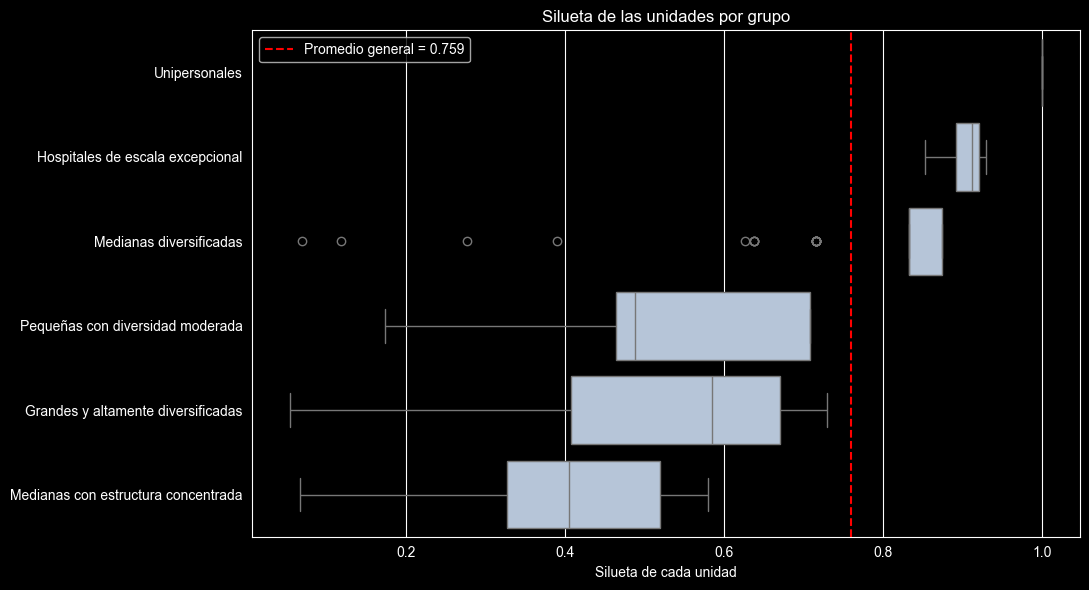

In [56]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=perfil_unidades,
    x="silueta",
    y="perfil_cluster",
    order=silueta_por_grupo.index,
    color="lightsteelblue"
)

plt.axvline(
    perfil_unidades["silueta"].mean(),
    color="red",
    linestyle="--",
    label="Promedio general = 0.759"
)

plt.title("Silueta de las unidades por grupo")
plt.xlabel("Silueta de cada unidad")
plt.ylabel("")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretación de la silueta por grupo

Ninguna unidad tiene silueta negativa, por lo que no hay unidades claramente asignadas al grupo
equivocado.

El grupo de unipersonales tiene una silueta perfecta de 1 porque sus 89 unidades tienen exactamente
los mismos valores. Los hospitales de escala excepcional (0.901) y las medianas diversificadas (0.797)
también están muy bien definidos, aunque en las medianas diversificadas hay unas pocas unidades con
silueta baja, que aparecen como puntos aislados en el gráfico. Los grupos de pequeñas (0.534) y grandes (0.523) tienen una calidad
aceptable. El grupo más débil es el de medianas con estructura concentrada (0.381): sus unidades
están más cerca de los grupos vecinos y algunas tienen una silueta cercana a 0.

### Efecto de las unidades con una sola jefatura

Como las 89 unidades unipersonales tienen silueta 1, elevan el promedio general. Para medir la calidad
real del resto de los grupos se calcula la silueta sin ellas. Además, se repite K-Means solo con las
unidades que tienen más de una jefatura, para comprobar si se obtienen los mismos grupos.

In [57]:
varias_jefaturas = perfil_unidades["total_jefaturas"] > 1

silueta_sin_unipersonales = silhouette_score(
    X_scaled[varias_jefaturas],
    perfil_unidades.loc[varias_jefaturas, "cluster_k6"]
)

print("Unidades con más de una jefatura:", varias_jefaturas.sum())
print("Silhouette sin unipersonales:", round(silueta_sin_unipersonales, 3))

Unidades con más de una jefatura: 195
Silhouette sin unipersonales: 0.649


In [58]:
modelo_sin_unipersonales = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20
)

grupos_sin_unipersonales = modelo_sin_unipersonales.fit_predict(X_scaled[varias_jefaturas])

pd.crosstab(
    perfil_unidades.loc[varias_jefaturas, "perfil_cluster"],
    grupos_sin_unipersonales,
    rownames=["Perfil en el modelo con K = 6"],
    colnames=["Grupo al repetir K-Means sin unipersonales"]
)

Grupo al repetir K-Means sin unipersonales,0,1,2,3,4
Perfil en el modelo con K = 6,,,,,
Grandes y altamente diversificadas,35,0,0,0,0
Hospitales de escala excepcional,0,0,0,0,4
Medianas con estructura concentrada,0,0,0,29,0
Medianas diversificadas,0,0,98,0,0
Pequeñas con diversidad moderada,0,29,0,0,0


### Interpretación

Sin las unidades unipersonales, el Silhouette Score baja de 0.759 a 0.649. El valor sigue por encima
del criterio de éxito de 0.5 definido en la sección 1.4, por lo que la estructura de grupos se
mantiene bien definida aunque se excluya ese bloque.

Al repetir K-Means con K = 5 solo sobre las 195 unidades con más de una jefatura, cada perfil del
modelo original queda completo en un solo grupo nuevo. Es decir, se obtienen exactamente los mismos
cinco grupos. Esto demuestra que los perfiles son estables y que no dependen de la presencia de las
unidades unipersonales.

### Separación de los grupos en dos dimensiones

Para ver si los grupos se superponen, se reducen las tres variables a dos componentes con análisis de
componentes principales (PCA) y se grafican las unidades coloreadas por grupo junto con el centro de
cada grupo.

In [59]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
componentes = pca.fit_transform(X_scaled)

perfil_unidades["componente_1"] = componentes[:, 0]
perfil_unidades["componente_2"] = componentes[:, 1]

print("Varianza explicada por cada componente:", pca.explained_variance_ratio_.round(3))
print("Varianza explicada en total:", round(pca.explained_variance_ratio_.sum(), 3))

Varianza explicada por cada componente: [0.92  0.072]
Varianza explicada en total: 0.992


C:\Users\Claret\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


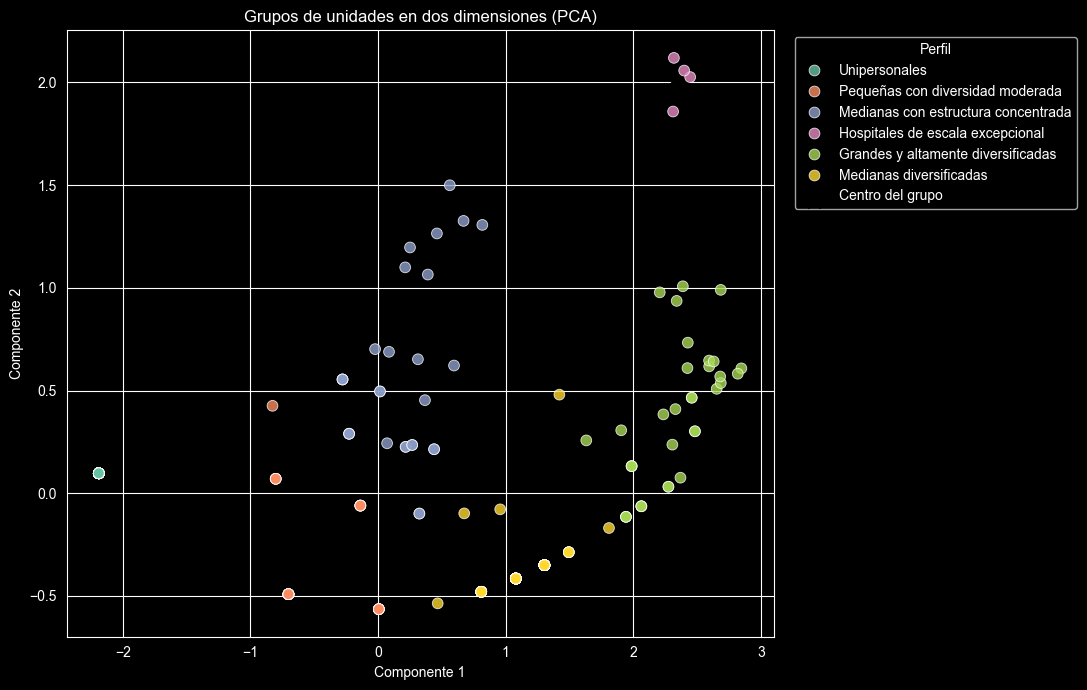

In [60]:
centros_pca = pca.transform(modelo_k6.cluster_centers_)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=perfil_unidades,
    x="componente_1",
    y="componente_2",
    hue="perfil_cluster",
    palette="Set2",
    s=60,
    alpha=0.8,
    zorder=3
)

plt.scatter(
    centros_pca[:, 0],
    centros_pca[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centro del grupo",
    zorder=2
)

plt.title("Grupos de unidades en dos dimensiones (PCA)")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.legend(title="Perfil", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Interpretación

Las dos componentes explican el 99.2 % de la variación de las tres variables, por lo que el gráfico
representa casi por completo la posición real de las unidades. Los grupos ocupan zonas distintas y
sus centros están bien separados. El bloque de unipersonales aparece como un solo punto porque todas
sus unidades son idénticas. La zona donde los grupos están más cerca es entre las medianas con
estructura concentrada y sus vecinos, lo que coincide con su silueta más baja.

### Comparación de los perfiles (gráfico de radar)

El gráfico de radar compara los perfiles en cuatro características: tamaño, puestos distintos,
diversidad y concentración. Para que todas se puedan ver en la misma escala, el promedio de cada grupo
se lleva a una escala de 0 a 1, donde 0 corresponde al grupo con el valor más bajo y 1 al grupo con el
valor más alto. Se dibuja un radar por cada perfil para que sea más fácil compararlos.

In [61]:
variables_radar = {
    "total_jefaturas": "Tamaño",
    "puestos_distintos": "Puestos distintos",
    "entropia_puestos": "Diversidad",
    "proporcion_puesto_principal": "Concentración"
}

promedios_radar = (
    perfil_unidades.groupby("perfil_cluster")[list(variables_radar)]
    .mean()
    .rename(columns=variables_radar)
)

radar_escalado = (promedios_radar - promedios_radar.min()) / (promedios_radar.max() - promedios_radar.min())

orden_perfiles = perfil_k6.sort_values("promedio_jefaturas")["perfil_cluster"]
radar_escalado = radar_escalado.loc[orden_perfiles]

radar_escalado.round(2)

,Tamaño,Puestos distintos,Diversidad,Concentración
perfil_cluster,,,,
Unipersonales,0.00,0.00,0.00,1.00
Pequeñas con diversidad moderada,0.03,0.06,0.32,0.40
Medianas diversificadas,0.09,0.24,0.69,0.02
Medianas con estructura concentrada,0.14,0.12,0.40,0.48
Grandes y altamente diversificadas,0.30,0.66,1.00,0.00
Hospitales de escala excepcional,1.00,1.00,0.85,0.37


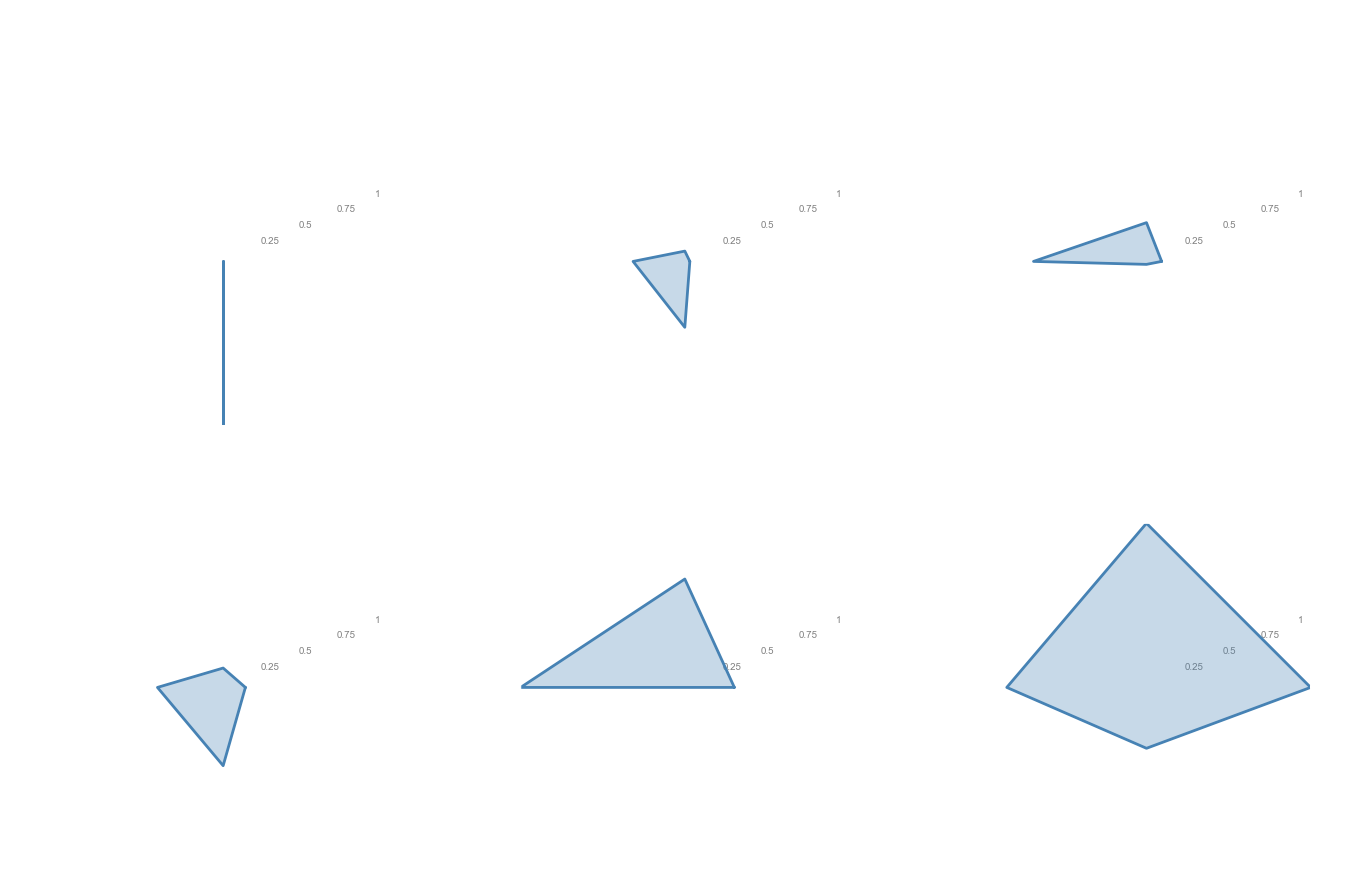

In [62]:
etiquetas = radar_escalado.columns.tolist()
angulos = np.linspace(0, 2 * np.pi, len(etiquetas), endpoint=False).tolist()
angulos += angulos[:1]

fig, axes = plt.subplots(2, 3, figsize=(14, 9), subplot_kw={"polar": True})
fig.patch.set_facecolor("white")

for ax, grupo in zip(axes.flatten(), radar_escalado.index):
    valores = radar_escalado.loc[grupo].tolist()
    valores += valores[:1]

    ax.set_facecolor("white")
    ax.plot(angulos, valores, color="steelblue", linewidth=2)
    ax.fill(angulos, valores, color="steelblue", alpha=0.3)

    ax.set_xticks(angulos[:-1])
    ax.set_xticklabels(etiquetas, fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.5, 0.75, 1])
    ax.set_yticklabels(["0.25", "0.5", "0.75", "1"], fontsize=7, color="gray")
    ax.set_title(grupo, fontsize=11, pad=15)

fig.suptitle("Perfil de cada grupo (escala de 0 a 1 entre grupos)", fontsize=14)
plt.tight_layout()
plt.show()

### Interpretación del gráfico de radar

Cada perfil tiene una forma distinta:

Las unipersonales solo tienen valor en concentración: todas sus jefaturas son un único puesto.

Las pequeñas con diversidad moderada y las medianas con estructura concentrada tienen formas parecidas,
con valores bajos o intermedios en todo, pero las medianas concentradas son algo más grandes y tienen
más concentración en un mismo puesto. Las medianas concentradas son principalmente oficinas centrales
(direcciones y áreas de sede), donde predomina un mismo tipo de jefatura.

Las medianas diversificadas tienen un tamaño parecido al de las concentradas, pero mucha más diversidad
y casi ninguna concentración. Son principalmente áreas de salud, con puestos variados.

Las grandes altamente diversificadas tienen la mayor diversidad y la menor concentración: sus
jefaturas están repartidas entre muchos puestos diferentes.

Los hospitales de escala excepcional tienen el mayor tamaño y la mayor cantidad de puestos distintos,
pero su diversidad es menor que la de las grandes y su concentración es intermedia. Esto se debe a que
en los cuatro hospitales el puesto Médico Jefe 3 ocupa entre el 44 % y el 50 % de las jefaturas.

Esto confirma que el tamaño por sí solo no basta para describir la estructura de una unidad.

## 4.7 Guardar los resultados del modelado

Se guarda la tabla de unidades con el grupo asignado a cada una, para usarla en la evaluación y en la
predicción.

In [63]:
perfil_unidades.to_csv(
    "../data/processed/perfil_unidades_clusters.csv",
    index=False,
    encoding="utf-8"
)

print("Archivo guardado: data/processed/perfil_unidades_clusters.csv")
perfil_unidades["perfil_cluster"].value_counts()

Archivo guardado: data/processed/perfil_unidades_clusters.csv


perfil_cluster
Medianas diversificadas                98
Unipersonales                          89
Grandes y altamente diversificadas     35
Pequeñas con diversidad moderada       29
Medianas con estructura concentrada    29
Hospitales de escala excepcional        4
Name: count, dtype: int64